In [1]:
import matplotlib.pyplot as plt
import numpy as np
import os
import pandas as pd
from pathlib import Path
import seaborn as sns
from pathlib import Path
import sys

from utils import pq_to_xy, plot_spatial_kernel_hex
from utils.spatial_RF import compute_kernel
from utils.plotting import plot_example_RFs, plot_kernels_on_eye, receptive_fields_grid
from matplotlib.colors import TwoSlopeNorm,  Normalize

In [2]:
data_dir = Path('results/connectome')

edges       = pd.read_feather(data_dir / 'edgelist_OL_columnar_T4T5norm.feather')
nodes_df    = pd.read_feather(data_dir / 'nodes_OL_columnar_T4T5norm.feather')

# edges       = pd.read_feather(data_dir / 'edgelist_OL_columnar.feather')
# nodes_df    = pd.read_feather(data_dir / 'nodes_OL_columnar.feather')

print("Available celltypes")
print("Number: ", nodes_df['cell_type'].nunique())
print(nodes_df['cell_type'].unique())

Available celltypes
Number:  24
['C2' 'C3' 'L1' 'L2' 'L3' 'L5' 'Mi1' 'Mi4' 'Mi9' 'T1' 'Tm1' 'Tm2' 'Tm20'
 'Tm4' 'Tm9' 'T4a' 'T4b' 'T4c' 'T4d' 'T5a' 'T5b' 'T5c' 'T5d' 'CT1']


In [3]:
POST_TYPE = "T5b"
RADIUS    = 2
THRESHOLD = 1.0

# Choose what each matrix entry should contain
VALUE_COL = "count"   # or "count", depending on your full-kernel columns

kernels = {}
full_kernels = {}

POST_TYPE_inputs = edges.query("post_cell_type == @POST_TYPE").copy()
input_types = POST_TYPE_inputs["pre_cell_type"].unique()

# Compute per-input full kernels
for pre_type in input_types:
    mean_kernel, full = compute_kernel(
        edges,
        pre_type=pre_type,
        post_type=POST_TYPE,
        radius=RADIUS,
    )

    kernels[pre_type] = mean_kernel
    full_kernels[pre_type] = full

In [4]:
MEAN_VALUE_COL = "mean_count"

kernel_strength = {
    pre_type: kernels[pre_type][MEAN_VALUE_COL].abs().max()
    for pre_type in input_types
}

input_types = [
    pre_type
    for pre_type in input_types
    if kernel_strength[pre_type] >= THRESHOLD
]

input_types = sorted(
    input_types,
    key=lambda pre_type: kernel_strength[pre_type],
    reverse=True,
)

print("Above threshold types:", input_types)

Above threshold types: ['Tm2', 'Tm9', 'CT1', 'Tm1', 'Tm4', 'T5b']


In [5]:
all_full = []

for pre_type in input_types:
    full = full_kernels[pre_type].copy()
    full["pre_type"] = pre_type
    full["offset"] = (
        full["dp"].astype(int).astype(str)
        + "_"
        + full["dq"].astype(int).astype(str)
    )
    full["feature"] = (
        full["pre_type"].astype(str)
        + "__"
        + full["offset"].astype(str)
    )

    all_full.append(full)

all_full = pd.concat(all_full, ignore_index=True)
all_full

,post,target_p,target_q,post_side,dp,dq,count,signed_count,source_p,source_q,pre_cell_type,post_cell_type,pre_type,offset,feature
0,98389,6.0,-10.0,right,-2,-2,5.0,5.0,4.0,-12.0,Tm2,T5b,Tm2,-2_-2,Tm2__-2_-2
1,98389,6.0,-10.0,right,-2,-1,0.0,0.0,4.0,-11.0,Tm2,T5b,Tm2,-2_-1,Tm2__-2_-1
2,98389,6.0,-10.0,right,-2,0,0.0,0.0,4.0,-10.0,Tm2,T5b,Tm2,-2_0,Tm2__-2_0
3,98389,6.0,-10.0,right,-1,-2,0.0,0.0,5.0,-12.0,Tm2,T5b,Tm2,-1_-2,Tm2__-1_-2
4,98389,6.0,-10.0,right,-1,-1,9.0,9.0,5.0,-11.0,Tm2,T5b,Tm2,-1_-1,Tm2__-1_-1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
98491,160169,-14.0,-3.0,right,1,1,0.0,0.0,-13.0,-2.0,T5b,T5b,T5b,1_1,T5b__1_1
98492,160169,-14.0,-3.0,right,1,2,0.0,0.0,-13.0,-1.0,T5b,T5b,T5b,1_2,T5b__1_2
98493,160169,-14.0,-3.0,right,2,0,0.0,0.0,-12.0,-3.0,T5b,T5b,T5b,2_0,T5b__2_0
98494,160169,-14.0,-3.0,right,2,1,0.0,0.0,-12.0,-2.0,T5b,T5b,T5b,2_1,T5b__2_1


In [6]:
input_matrix = (
    all_full
    .pivot_table(
        index="post",
        columns="feature",
        values=VALUE_COL,
        aggfunc="sum",
        fill_value=0,
    )
    .rename_axis(columns=None)
)

input_matrix.shape

(836, 114)

In [7]:
input_matrix

,CT1__-1_-1,CT1__-1_-2,CT1__-1_0,CT1__-1_1,CT1__-2_-1,CT1__-2_-2,CT1__-2_0,CT1__0_-1,CT1__0_-2,CT1__0_0,...,Tm9__0_0,Tm9__0_1,Tm9__0_2,Tm9__1_-1,Tm9__1_0,Tm9__1_1,Tm9__1_2,Tm9__2_0,Tm9__2_1,Tm9__2_2
post,,,,,,,,,,,,,,,,,,,,,
80374,0.0,0.0,20.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,5.0,0.0,0.0,36.0,0.0,0.0,0.0,0.0,0.0
81491,0.0,0.0,9.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,5.0,10.0,0.0,0.0,0.0,0.0,0.0
81721,0.0,0.0,12.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,15.0,0.0,0.0,0.0,15.0,0.0,0.0,0.0,0.0,0.0
83167,0.0,0.0,10.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,6.0,0.0,0.0,0.0,7.0,0.0,0.0,0.0,0.0,0.0
83175,0.0,0.0,17.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,7.0,0.0,0.0,0.0,17.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
206612,0.0,0.0,14.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,13.0,0.0,0.0,0.0,0.0,6.0,0.0,0.0,0.0,0.0
220122,0.0,0.0,7.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
545103,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,7.0,...,9.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [8]:
from sklearn.decomposition import PCA, TruncatedSVD

X = input_matrix.copy()
n_components = min(X.shape) - 1
# X = X.div(
#     X.abs().sum(axis=1).replace(0, np.nan),
#     axis=0
# ).fillna(0)
pca = PCA(n_components=n_components)  

Z_pca = pca.fit_transform(X)   # scores: PC coordinates of each T4/5 cell

V_pca = pd.DataFrame(   #PC loading vectors / eigenvectors over offsets
    pca.components_,
    columns=X.columns,
    index=[f"PC{i+1}" for i in range(pca.n_components_)]
)

mu_pca = pd.Series(
    pca.mean_,
    index=X.columns,
    name="mean_kernel"
)

lambdas_pca = pd.Series( #variance explained by each PC / eigenvalues
    pca.explained_variance_,
    index=V_pca.index,
    name="eigenvalue"
)

explained_pca = pd.Series( #fraction of total variance explained by each PC
    pca.explained_variance_ratio_,
    index=V_pca.index,
    name="explained_variance_ratio"
)

scores_pca = pd.DataFrame(
    Z_pca,
    index=X.index,
    columns=V_pca.index
)

# Uncentered decomposition: raw motifs
svd = TruncatedSVD(n_components=n_components, random_state=0)
Z_svd = svd.fit_transform(X)

V_svd = pd.DataFrame(
    svd.components_,
    columns=X.columns,
    index=[f"SVD{i+1}" for i in range(svd.n_components)]
)

scores_svd = pd.DataFrame(
    Z_svd,
    index=X.index,
    columns=V_svd.index
)

energy = pd.Series(
    svd.singular_values_**2,
    index=V_svd.index,
    name="raw_energy"
)

energy_ratio = energy / energy.sum()
energy_ratio.name = "raw_energy_ratio"

explained_svd = pd.Series(
    svd.explained_variance_ratio_,
    index=V_svd.index,
    name="explained_variance_ratio"
)

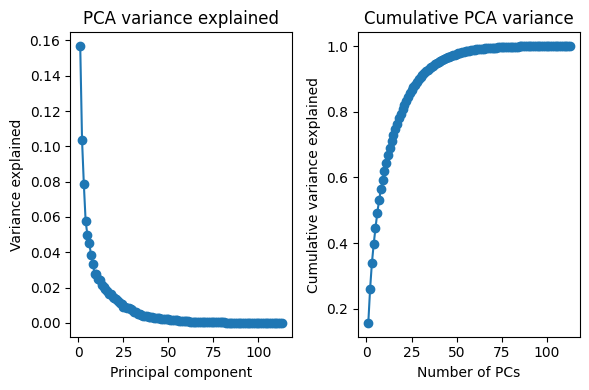

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(6, 4))

pc_nums = np.arange(1, len(explained_pca) + 1)

axes[0].plot(pc_nums, explained_pca  , marker="o")
axes[0].set_xlabel("Principal component")
axes[0].set_ylabel("Variance explained")
axes[0].set_title("PCA variance explained")

axes[1].plot(pc_nums, explained_pca.cumsum(), marker="o")
axes[1].set_xlabel("Number of PCs")
axes[1].set_ylabel("Cumulative variance explained")
axes[1].set_title("Cumulative PCA variance")

# show fewer ticks
# tick_step = 2  # or 3, depending on how crowded it is
# for ax in axes:
#     ax.set_xticks(pc_nums[::tick_step])
#     ax.tick_params(axis="x", rotation=45)

fig.tight_layout()
plt.show()

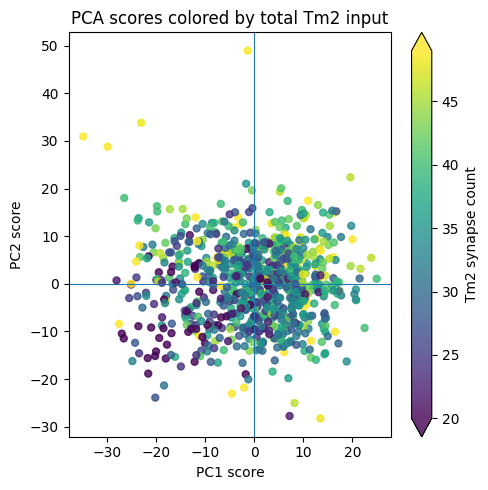

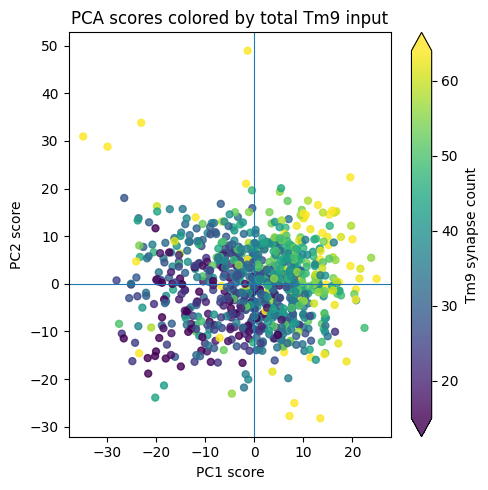

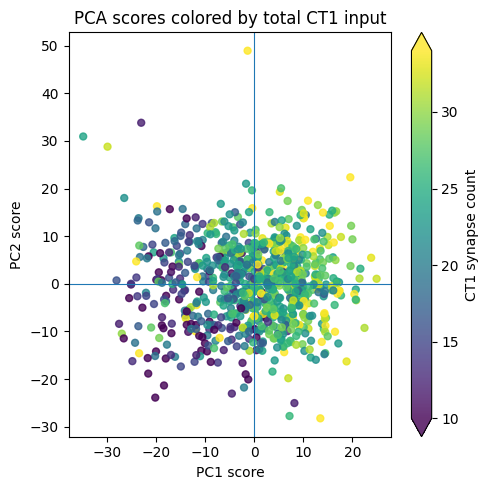

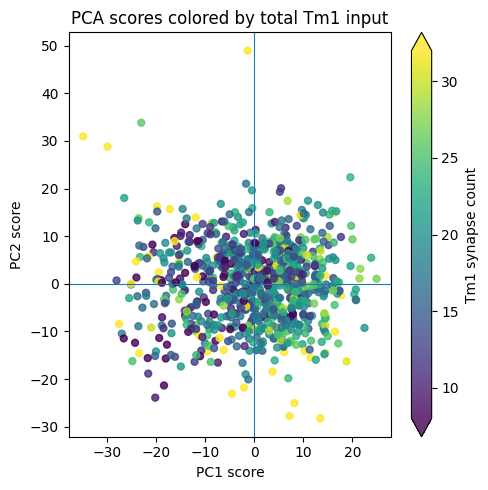

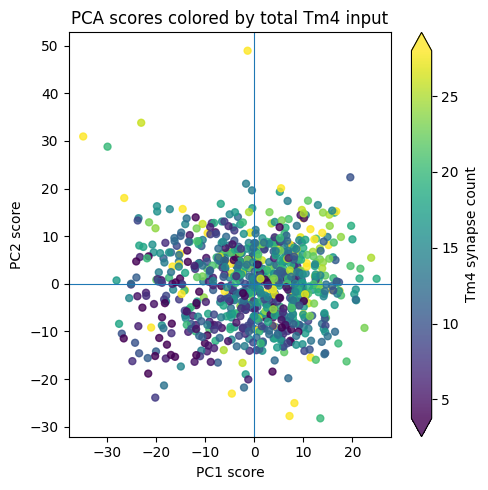

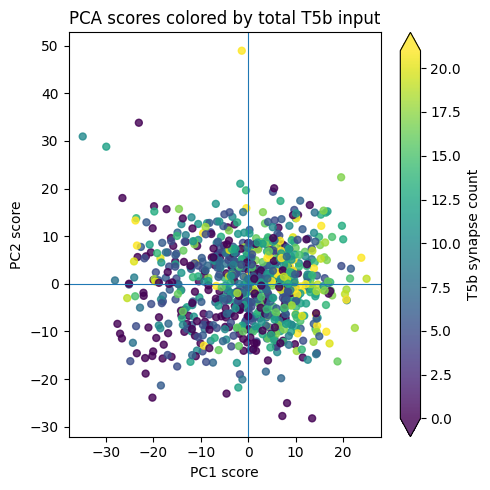

In [10]:
input_by_type = {}

for pre_type in input_types:
    input_by_type[pre_type] = (
        full_kernels[pre_type]
        .groupby("post")["count"]
        .sum()
    )

for pre_type in input_types:
    color_vals = input_by_type[pre_type].reindex(scores_pca.index).fillna(0)

    vmin = np.percentile(color_vals, 5)
    vmax = np.percentile(color_vals, 95)

    plt.figure(figsize=(5, 5))

    sc = plt.scatter(
        scores_pca["PC1"],
        scores_pca["PC2"],
        c=color_vals,
        s=25,
        alpha=0.8,
        vmin=vmin,
        vmax=vmax,
    )

    plt.axhline(0, linewidth=0.8)
    plt.axvline(0, linewidth=0.8)

    plt.xlabel("PC1 score")
    plt.ylabel("PC2 score")
    plt.title(f"PCA scores colored by total {pre_type} input")

    plt.colorbar(sc, label=f"{pre_type} synapse count", extend="both")
    plt.tight_layout()
    plt.show()

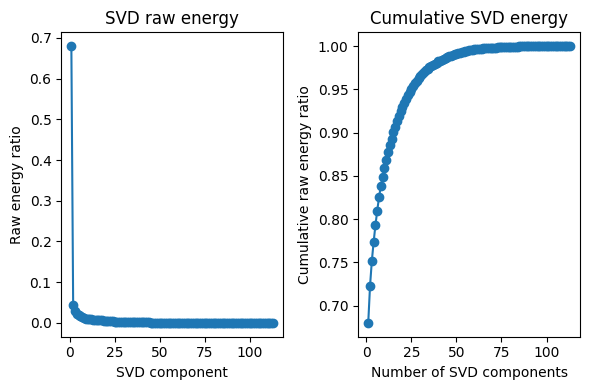

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(6, 4))

sv_nums = np.arange(1, len(energy_ratio) + 1)

axes[0].plot(sv_nums, energy_ratio, marker="o")
axes[0].set_xlabel("SVD component")
axes[0].set_ylabel("Raw energy ratio")
axes[0].set_title("SVD raw energy")

axes[1].plot(sv_nums, energy_ratio.cumsum(), marker="o")
axes[1].set_xlabel("Number of SVD components")
axes[1].set_ylabel("Cumulative raw energy ratio")
axes[1].set_title("Cumulative SVD energy")

# for ax in axes:
#     ax.set_xticks(sv_nums[::4])

fig.tight_layout()
plt.show()

In [12]:
def multi_vector_to_kernel(vec, value_name="loading"):
    rows = []

    for col, value in vec.items():
        pre_type, offset = col.split("__")
        dp, dq = offset.split("_")

        rows.append({
            "pre_type": pre_type,
            "dp": int(dp),
            "dq": int(dq),
            value_name: value,
        })

    return pd.DataFrame(rows)

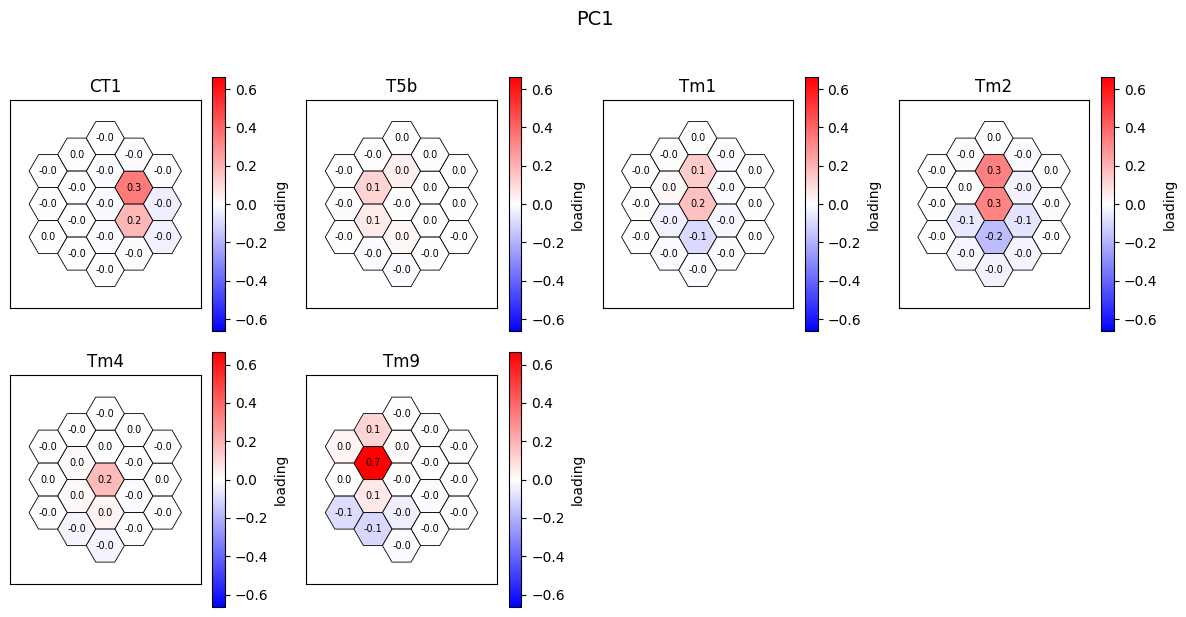

In [18]:
from matplotlib.colors import TwoSlopeNorm

def plot_multi_input_loading(
    V,
    component="PC1",
    radius=2,
    value_name="loading",
    ncols=4,
    global_scale=True,
):
    long_df = multi_vector_to_kernel(V.loc[component], value_name=value_name)

    input_types = long_df["pre_type"].unique()
    n_inputs = len(input_types)
    nrows = int(np.ceil(n_inputs / ncols))

    if global_scale:
        vmax = np.abs(long_df[value_name]).max()
    else:
        vmax = None

    fig, axes = plt.subplots(
        nrows,
        ncols,
        figsize=(3 * ncols, 3 * nrows),
        squeeze=False,
    )

    for ax, pre in zip(axes.flat, input_types):
        sub = long_df[long_df["pre_type"] == pre]

        if not global_scale:
            vmax = np.abs(sub[value_name]).max()

        plt.sca(ax)

        plot_spatial_kernel_hex(
            sub,
            value_col=value_name,
            radius=radius,
            norm=TwoSlopeNorm(vcenter=0, vmin=-vmax, vmax=vmax),
            add_colorbar=True,
            ax=ax
        )

        ax.set_title(pre)

    # turn off unused axes
    for ax in axes.flat[n_inputs:]:
        ax.axis("off")

    fig.suptitle(component, y=1.02, fontsize=14)
    fig.tight_layout()
    plt.show()
    
plot_multi_input_loading(
    V_pca,
    component="PC1",
    radius=RADIUS,
    ncols=4,
)

In [22]:
long_df = multi_vector_to_kernel(V_pca.loc["PC1"], value_name="loading")
long_df

,pre_type,dp,dq,loading
0,CT1,-1,-1,-1.222037e-02
1,CT1,-1,-2,4.440892e-16
2,CT1,-1,0,3.440302e-01
3,CT1,-1,1,-4.341312e-02
4,CT1,-2,-1,-1.121873e-02
...,...,...,...,...
109,Tm9,1,1,-4.494598e-02
110,Tm9,1,2,-2.364076e-03
111,Tm9,2,0,-8.825682e-02
112,Tm9,2,1,-9.868831e-02


### All strong kernels for  given postsynaptic celltype

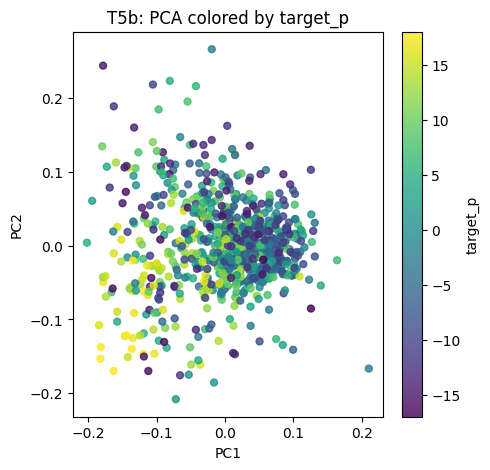

In [114]:
plt.figure(figsize=(5, 5))
sc = plt.scatter(
    pca_meta["PC1"],
    pca_meta["PC2"],
    c=pca_meta["target_p"],
    s=25,
    alpha=0.8,
)
plt.colorbar(sc, label="target_p")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title(f"{POST_TYPE}: PCA colored by target_p")
plt.show()

In [115]:
for pc in ["PC1", "PC2", "PC3", "PC4", "PC5"]:
    r = np.corrcoef(pca_meta[pc], pca_meta["target_p"])[0, 1]
    print(pc, "corr with target_p:", r)

PC1 corr with target_p: -0.2731223870706748
PC2 corr with target_p: -0.19600198194625362
PC3 corr with target_p: 0.25786371373827066
PC4 corr with target_p: 0.019488463371493223
PC5 corr with target_p: -0.1830953115313493


In [116]:
for pc in ["PC1", "PC2", "PC3", "PC4", "PC5"]:
    r = np.corrcoef(pca_meta[pc], pca_meta["target_q"])[0, 1]
    print(pc, "corr with target_q:", r)

PC1 corr with target_q: -0.2636271215358507
PC2 corr with target_q: 0.19818045813638946
PC3 corr with target_q: 0.029912353102385582
PC4 corr with target_q: -0.0666649501102055
PC5 corr with target_q: -0.019271093658662603


NameError: name 'pca_meta' is not defined

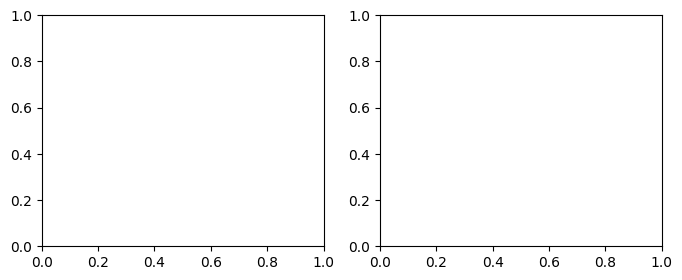

In [61]:
fig, axes = plt.subplots(1, 2, figsize=(8, 3))

axes[0].scatter(pca_meta["target_p"], pca_meta["PC1"], s=20, alpha=0.7)
axes[0].set_xlabel("target_p")
axes[0].set_ylabel("PC1")
axes[0].set_title("PC1 vs target_p")

axes[1].scatter(pca_meta["target_p"], pca_meta["PC3"], s=20, alpha=0.7)
axes[1].set_xlabel("target_p")
axes[1].set_ylabel("PC2")
axes[1].set_title("PC2 vs target_p")

plt.tight_layout()
plt.show()

In [118]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

coords = pca_meta[["target_p", "target_q"]].to_numpy()

for pc in ["PC1", "PC2", "PC3", "PC4", "PC5"]:
    y = pca_meta[pc].to_numpy()

    model = LinearRegression().fit(coords, y)
    yhat = model.predict(coords)

    print(pc, "R2 from target_p/q:", r2_score(y, yhat))

PC1 R2 from target_p/q: 0.09178191972324956
PC2 R2 from target_p/q: 0.18121578132915062
PC3 R2 from target_p/q: 0.08695405305925197
PC4 R2 from target_p/q: 0.009364728219174445
PC5 R2 from target_p/q: 0.04433215283046377


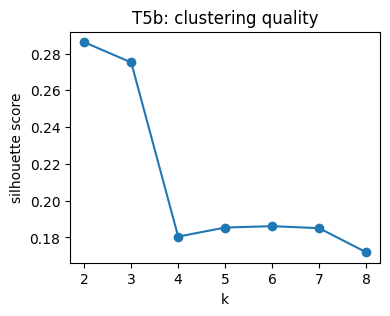

In [119]:
Z = pca_df[["PC1", "PC2", "PC3", "PC4", "PC5"]].to_numpy()
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

ks = range(2, 9)
sil_scores = []

for k in ks:
    labels = KMeans(n_clusters=k, random_state=0, n_init=50).fit_predict(Z)
    sil = silhouette_score(Z, labels)
    sil_scores.append(sil)

plt.figure(figsize=(4, 3))
plt.plot(list(ks), sil_scores, marker="o")
plt.xlabel("k")
plt.ylabel("silhouette score")
plt.title(f"{POST_TYPE}: clustering quality")
plt.show()

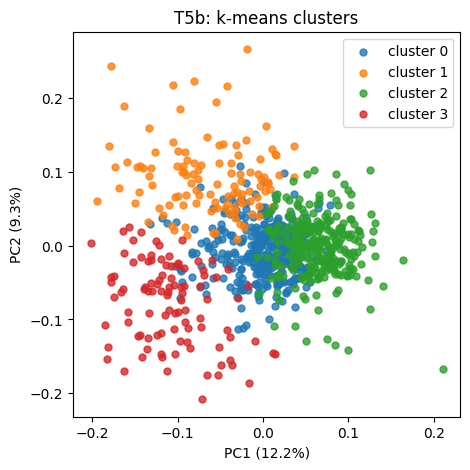

In [120]:
k = 4

labels = KMeans(
    n_clusters=k,
    random_state=0,
    n_init=100,
).fit_predict(Z)

pca_meta["cluster"] = labels

plt.figure(figsize=(5, 5))
for cl in sorted(pca_meta["cluster"].unique()):
    d = pca_meta[pca_meta["cluster"] == cl]
    plt.scatter(d["PC1"], d["PC2"], s=25, alpha=0.8, label=f"cluster {cl}")

plt.xlabel(f"PC1 ({explained[0]*100:.1f}%)")
plt.ylabel(f"PC2 ({explained[1]*100:.1f}%)")
plt.title(f"{POST_TYPE}: k-means clusters")
plt.legend()
plt.show()

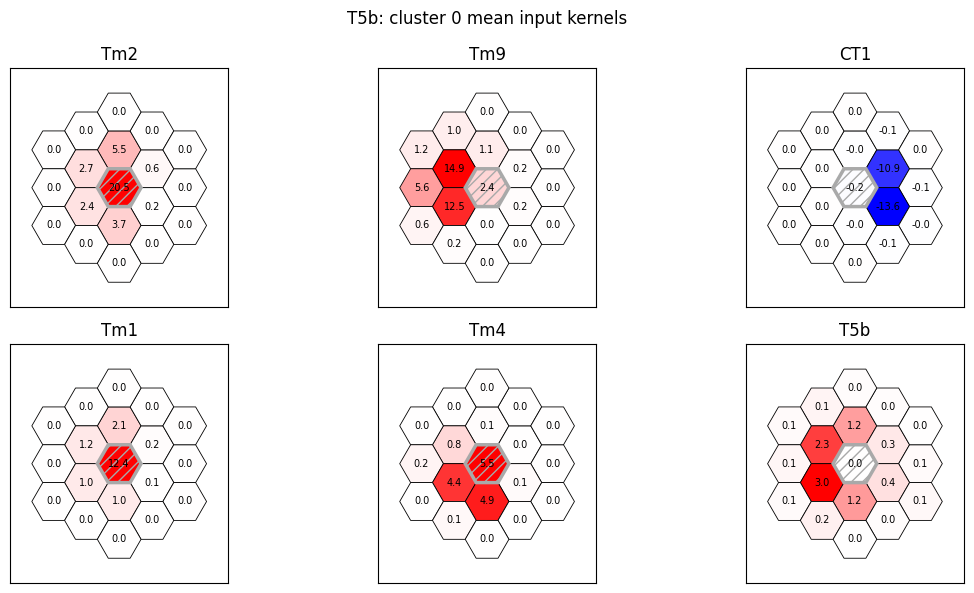

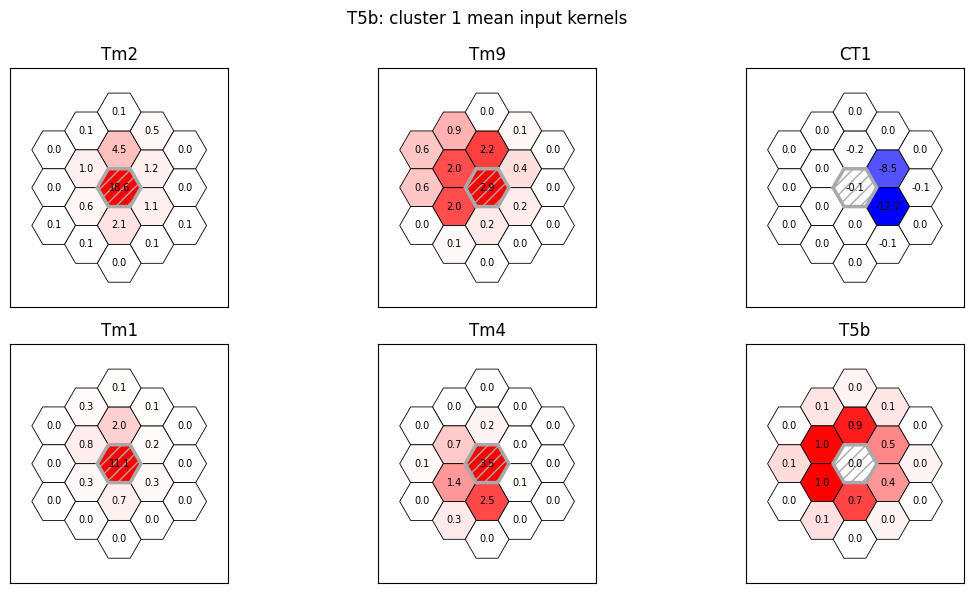

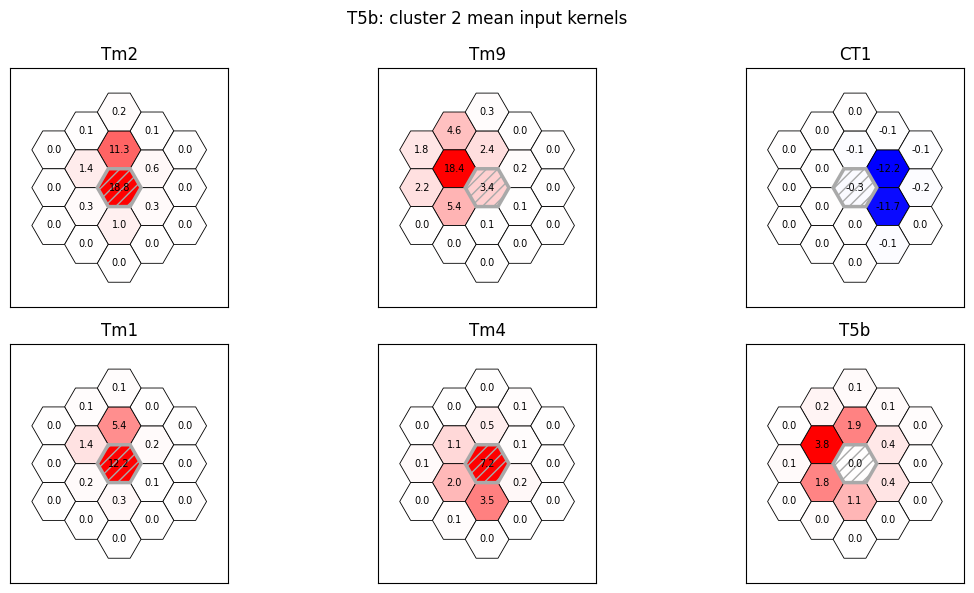

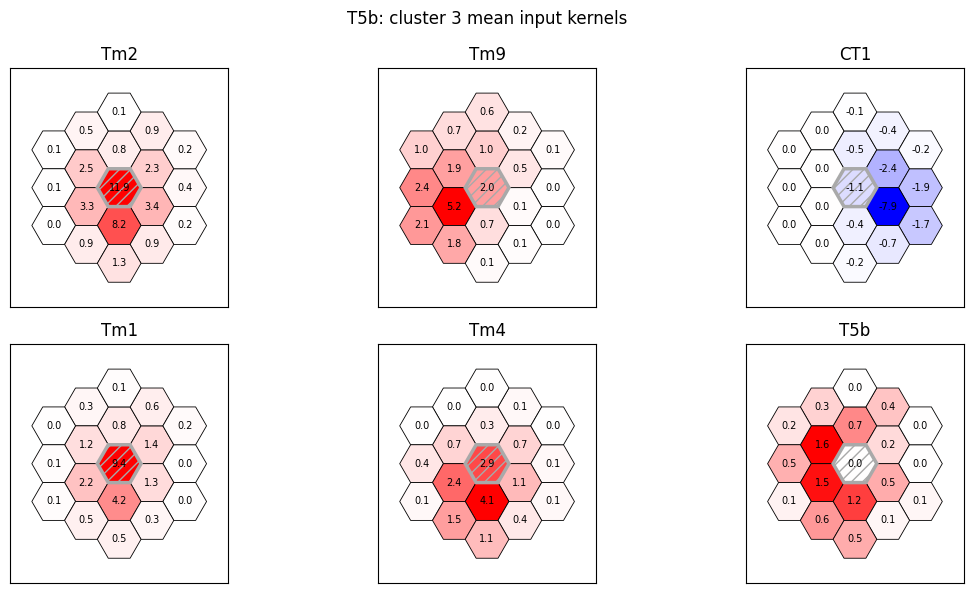

In [121]:
cluster_means = (
    T4b_input_matrix
    .join(pca_meta["cluster"])
    .groupby("cluster")
    .mean()
)
def feature_row_to_long(row, value_name="value"):
    df = row.rename(value_name).reset_index()
    df = df.rename(columns={"index": "feature"})

    df[["pre_type", "offset"]] = df["feature"].str.split("__", expand=True)
    df[["dp", "dq"]] = df["offset"].str.split("_", expand=True).astype(int)

    return df

top_inputs = input_types[:8]

for cl in sorted(cluster_means.index):
    cluster_long = feature_row_to_long(
        cluster_means.loc[cl],
        value_name="value"
    )

    fig, axes = plt.subplots(2, 3, figsize=(12, 6))
    axes = axes.ravel()

    for ax, pre_type in zip(axes, top_inputs):
        kernel = cluster_long.query("pre_type == @pre_type").copy()

        plot_spatial_kernel_hex(
            kernel,
            ax=ax,
            value_col="value",
            radius=RADIUS,
            cmap="bwr",
            title=pre_type,
        )

    fig.suptitle(f"{POST_TYPE}: cluster {cl} mean input kernels")
    plt.tight_layout()
    plt.show()

In [122]:
def pc_loading_to_long(pca, pc_idx, columns):
    """
    pc_idx is zero-indexed.
    For PC1 use pc_idx=0.
    """
    loading = pd.Series(
        pca.components_[pc_idx],
        index=columns,
        name="value"
    )

    df = loading.reset_index()
    df = df.rename(columns={"index": "feature"})

    df[["pre_type", "offset"]] = df["feature"].str.split("__", expand=True)
    df[["dp", "dq"]] = df["offset"].str.split("_", expand=True).astype(int)

    return df

pc1_long = pc_loading_to_long(
    pca,
    pc_idx=0,
    columns=X_shape.columns,
)

pc1_long.head()

,feature,value,pre_type,offset,dp,dq
0,CT1__-1_-1,1.582028e-02,CT1,-1_-1,-1,-1
1,CT1__-1_-2,-2.471861e-18,CT1,-1_-2,-1,-2
2,CT1__-1_0,-2.782762e-01,CT1,-1_0,-1,0
3,CT1__-1_1,5.116439e-02,CT1,-1_1,-1,1
4,CT1__-2_-1,3.277237e-03,CT1,-2_-1,-2,-1


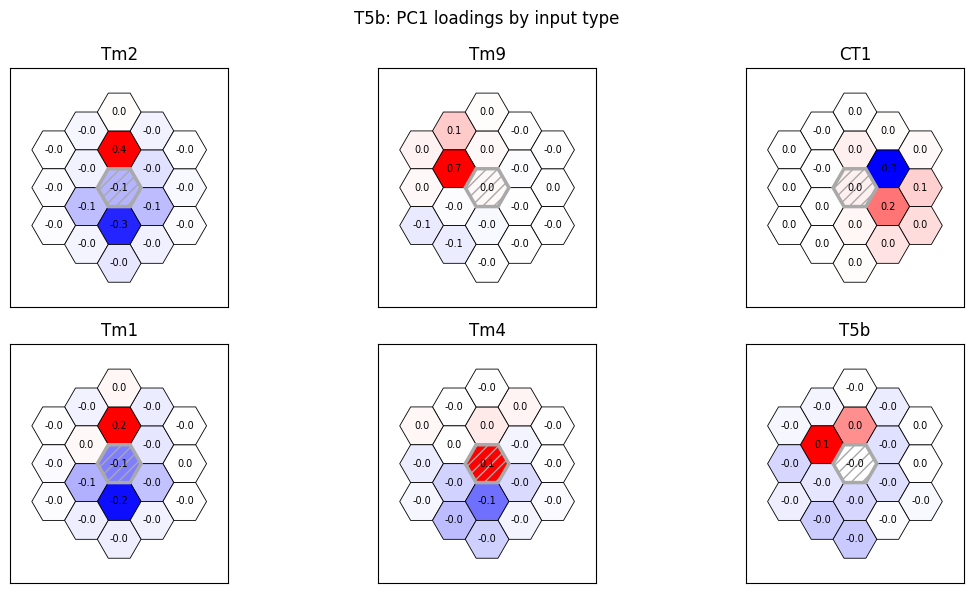

In [123]:
top_inputs = input_types[:8]

fig, axes = plt.subplots(2, 3, figsize=(12, 6))
axes = axes.ravel()

for ax, pre_type in zip(axes, top_inputs):
    kernel = pc1_long.query("pre_type == @pre_type").copy()

    plot_spatial_kernel_hex(
        kernel,
        ax=ax,
        value_col="value",
        radius=RADIUS,
        cmap="bwr",
        title=f"{pre_type}"
    )

fig.suptitle(f"{POST_TYPE}: PC1 loadings by input type")
plt.tight_layout()
plt.show()

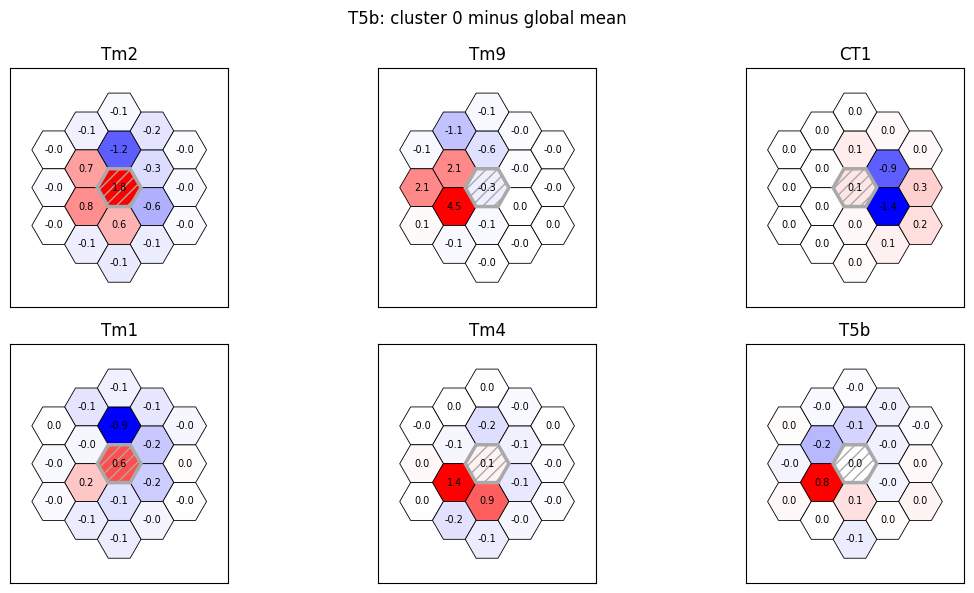

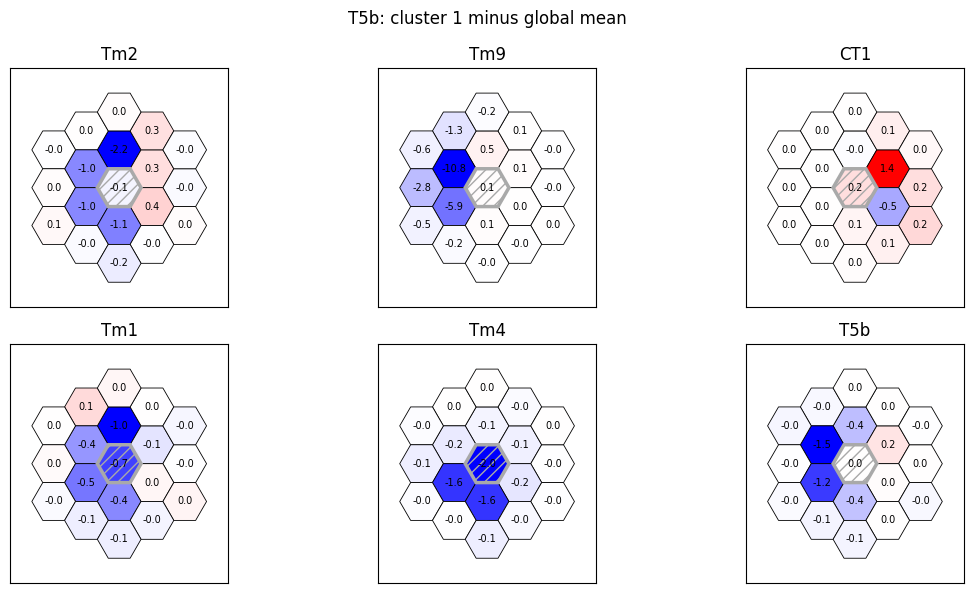

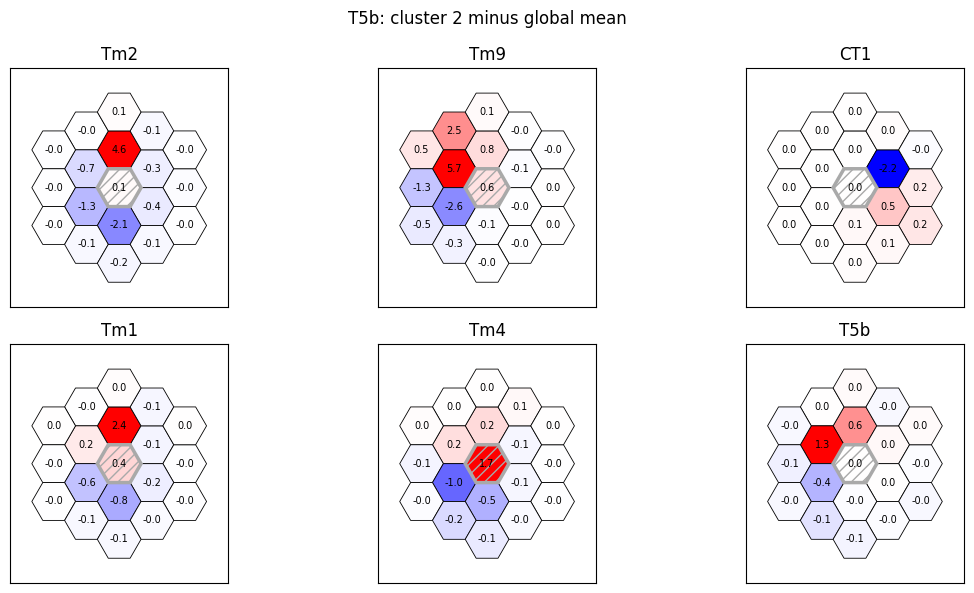

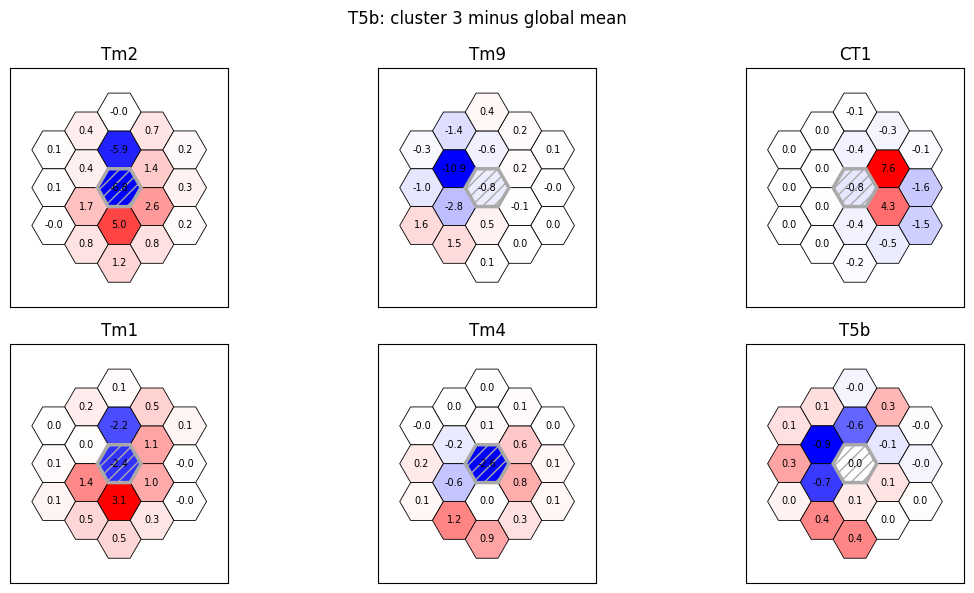

In [124]:
global_mean = T4b_input_matrix.mean(axis=0)

for cl in sorted(cluster_means.index):
    diff_row = cluster_means.loc[cl] - global_mean
    diff_long = feature_row_to_long(diff_row, value_name="value")

    fig, axes = plt.subplots(2, 3, figsize=(12, 6))
    axes = axes.ravel()

    for ax, pre_type in zip(axes, top_inputs):
        kernel = diff_long.query("pre_type == @pre_type").copy()

        plot_spatial_kernel_hex(
            kernel,
            ax=ax,
            value_col="value",
            radius=RADIUS,
            cmap="bwr",
            title=pre_type,
        )

    fig.suptitle(f"{POST_TYPE}: cluster {cl} minus global mean")
    plt.tight_layout()
    plt.show()

## Single pair

In [125]:
x, y = pq_to_xy(
    pca_spatial["target_p"].to_numpy(),
    pca_spatial["target_q"].to_numpy(),
    hexsize=1.0,
    rotate=-np.pi / 6,
)

plt.figure(figsize=(6, 5))

sc = plt.scatter(
    x,
    y,
    c=pca_spatial["PC1"],
    s=30,
)

plt.axis("equal")
plt.xlabel("x")
plt.ylabel("y")
plt.title("PC1 score across T4b columns")
plt.colorbar(sc, label="PC1 score")
plt.tight_layout()
plt.show()

NameError: name 'pca_spatial' is not defined